In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd

os.listdir('/content/drive')

['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

os.listdir('/content/drive/MyDrive')

In [ ]:
os.listdir('/content/drive/MyDrive')

['Colab Notebooks', 'Nikita Singh 050', 'AI_HOUSE_PRICE']

In [ ]:
os.listdir('/content/drive/MyDrive/AI_HOUSE_PRICE/DATASET')

['test.csv', 'train.csv']

In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/AI_HOUSE_PRICE/DATASET/train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/AI_HOUSE_PRICE/DATASET/test.csv')

print("Training dataset:", df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (1460, 81)
Testing dataset: (1459, 80)


In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Condition2         0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

numeric_features = X.select_dtypes(include=['number']).columns
categorical_features = X.select_dtypes(include=['object']).columns

numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preprocessing setup completed!")
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Data preprocessing setup completed!
Training data: (1168, 80)
Validation data: (292, 80)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "training completed!")

print("All 3 models trained successfully!")


Linear Regression training completed!
Decision Tree training completed!
Random Forest training completed!
All 3 models trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, pipeline in trained_models.items():
    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = mean_squared_error(y_val, predictions) ** 0.5
    r2 = r2_score(y_val, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(2))

               Model       MAE      RMSE  R2 Score
0  Linear Regression  20485.66  31327.80      0.87
1      Decision Tree  27582.67  41784.63      0.77
2      Random Forest  17523.68  28493.75      0.89


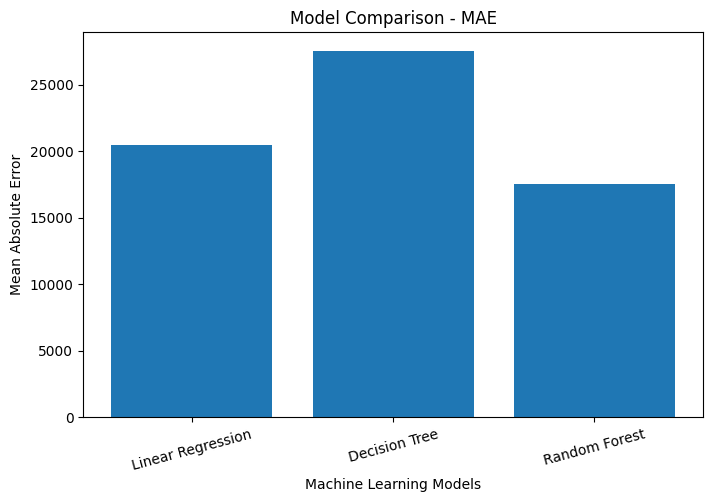

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(results_df['Model'], results_df['MAE'])
plt.title('Model Comparison - MAE')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=15)
plt.show()

In [ ]:
best_model_name = results_df.sort_values('MAE').iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: Random Forest


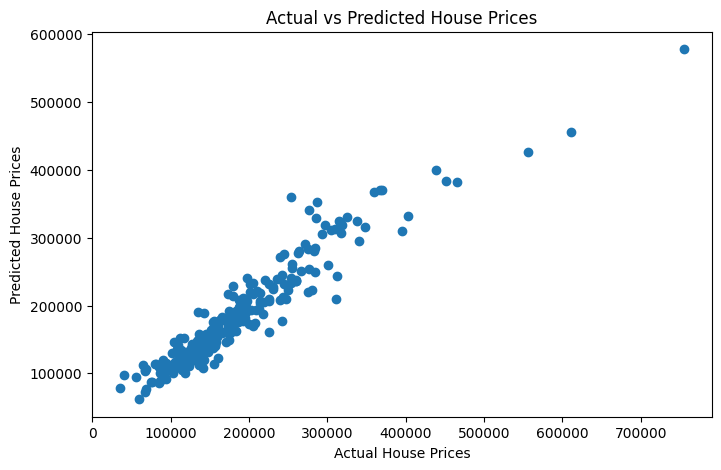

In [ ]:
best_model = trained_models[best_model_name]
predictions = best_model.predict(X_val)

plt.figure(figsize=(8,5))
plt.scatter(y_val, predictions)
plt.xlabel('Actual House Prices')
plt.ylabel('Predicted House Prices')
plt.title('Actual vs Predicted House Prices')
plt.show()

In [ ]:
final_predictions = best_model.predict(test_df)

prediction_df = pd.DataFrame({
    'Id': test_df['Id'],
    'Predicted Sale Price': final_predictions
})

prediction_df.head(10)

,Id,Predicted Sale Price
0,1461,131281.50
1,1462,152591.25
2,1463,177775.50
3,1464,187719.02
4,1465,205673.79
5,1466,184306.32
6,1467,170968.60
7,1468,177581.18
8,1469,181538.17
9,1470,122527.33


In [ ]:
prediction_df.to_csv(
    '/content/drive/MyDrive/AI_HOUSE_PRICE/predictions.csv',
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [ ]:
results_df.to_csv(
    '/content/drive/MyDrive/AI_HOUSE_PRICE/model_results.csv',
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [ ]:
print("HOUSE PRICE PREDICTION PROJECT")
print("--------------------------------")

print("Models Used:")
for name in trained_models:
    print("-", name)

print("\nBest Model:", best_model_name)

print("\nModel Performance:")
print(results_df.round(2))

print("\nProject Completed Successfully!")

HOUSE PRICE PREDICTION PROJECT
--------------------------------
Models Used:
- Linear Regression
- Decision Tree
- Random Forest

Best Model: Random Forest

Model Performance:
               Model       MAE      RMSE  R2 Score
0  Linear Regression  20485.66  31327.80      0.87
1      Decision Tree  27582.67  41784.63      0.77
2      Random Forest  17523.68  28493.75      0.89

Project Completed Successfully!
